<a href="https://colab.research.google.com/github/PaoloniCoder/MozartAI/blob/main/m3_audio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys, os, glob, io, tarfile
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive, files
drive.mount('/content/drive')
!pip -q install pretty_midi

UTENTE = 'martinopaoloni-ux'
BRANCH = 'main'          # il branch dove hai messo src/audio.py

!rm -rf /content/MozartAI
!git clone -b {BRANCH} https://github.com/{UTENTE}/MozartAI.git /content/MozartAI
percorsi = glob.glob('/content/MozartAI/**/audio.py', recursive=True)
if percorsi:
    sys.path.insert(0, os.path.dirname(percorsi[0]))
else:
    print("audio.py non è su GitHub: caricalo a mano")
    files.upload()
    sys.path.insert(0, '/content')

import pretty_midi
from audio import midi_to_audio, staves_to_midi, ErroreAudio
from midi_convert import tokens_to_midi      # serve alla cella 6
from IPython.display import Audio
print("Import ok")

Mounted at /content/drive
Cloning into '/content/MozartAI'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (138/138), done.
remote: Compressing objects: 100% (131/131), done.
remote: Total 138 (delta 59), reused 8 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (138/138), 8.67 MiB | 9.24 MiB/s, done.
Resolving deltas: 100% (59/59), done.
Import ok


In [2]:
ARCHIVE = '/content/drive/MyDrive/MozartAI/data/primus.tgz'
esempi, parziali = [], {}
with tarfile.open(ARCHIVE, 'r:gz') as tar:
    for m in tar:
        nome = os.path.basename(m.name)
        if not m.isfile() or nome.startswith('._'):
            continue
        cartella = os.path.dirname(m.name)
        if nome.endswith('.semantic'):
            parziali.setdefault(cartella, {})['sem'] = tar.extractfile(m).read().decode('utf-8').split()
        elif nome.endswith('.mid'):
            parziali.setdefault(cartella, {})['mid'] = tar.extractfile(m).read()
        d = parziali.get(cartella, {})
        if 'sem' in d and 'mid' in d:
            esempi.append(parziali.pop(cartella))
            if len(esempi) == 2:
                break

pm1 = pretty_midi.PrettyMIDI(io.BytesIO(esempi[0]['mid']))
pm2 = pretty_midi.PrettyMIDI(io.BytesIO(esempi[1]['mid']))
for i, pm in enumerate((pm1, pm2), 1):
    print(f"Esempio {i}: {sum(len(s.notes) for s in pm.instruments)} note, {pm.get_end_time():.1f} secondi")

print("Esempio 1, sintetizzatore di pretty_midi:")
Audio(pm1.synthesize(fs=22050), rate=22050)

Esempio 1: 13 note, 10.0 secondi
Esempio 2: 20 note, 8.0 secondi
Esempio 1, sintetizzatore di pretty_midi:


frequenza: 22050 | tipo: int16 | campioni: (228441,) | durata: 10.4 s
picco: 26214 su 32767 (deve essere sotto)


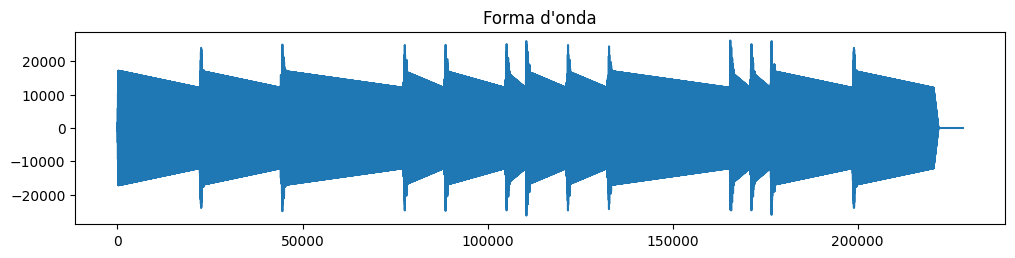

In [3]:
fs, onda = midi_to_audio(pm1)
print("frequenza:", fs, "| tipo:", onda.dtype, "| campioni:", onda.shape, "| durata:", round(len(onda) / fs, 1), "s")
print("picco:", np.abs(onda).max(), "su 32767 (deve essere sotto)")
assert np.abs(onda).max() < 32767

plt.figure(figsize=(12, 2.5)); plt.plot(onda); plt.title("Forma d'onda"); plt.show()
Audio(onda, rate=fs)

In [4]:
brano = staves_to_midi([pm1, pm2])

n1 = sum(len(s.notes) for s in pm1.instruments)
n2 = sum(len(s.notes) for s in pm2.instruments)
note = sorted(brano.instruments[0].notes, key=lambda n: (n.start, n.pitch))
print("Note: rigo 1 =", n1, "| rigo 2 =", n2, "| brano unito =", len(note))
print("Il rigo 1 finisce a", round(max(n.end for s in pm1.instruments for n in s.notes), 2), "s")
print("La prima nota del rigo 2 parte a", round(note[n1].start, 2), "s")

fs, onda = midi_to_audio(brano)
Audio(onda, rate=fs)

Note: rigo 1 = 13 | rigo 2 = 20 | brano unito = 33
Il rigo 1 finisce a 10.0 s
La prima nota del rigo 2 parte a 10.0 s


In [5]:
for nome, lista in [('lista vuota', []), ('righi senza note', [pretty_midi.PrettyMIDI(), None])]:
    try:
        staves_to_midi(lista)
    except ErroreAudio as e:
        print(f"{nome:18s} -> messaggio: {e}")

avvisi = []
brano = staves_to_midi([pm1, pretty_midi.PrettyMIDI(), pm2], avvisi=avvisi)
print("Rigo vuoto in mezzo: brano ok, avvisi:", avvisi)

lista vuota        -> messaggio: Nessun rigo da unire: non è stato riconosciuto nessun pentagramma nella foto.
righi senza note   -> messaggio: I righi riconosciuti non contengono nessuna nota: non c'è niente da unire.
Rigo vuoto in mezzo: brano ok, avvisi: ['Il rigo 2 non ha note: saltato.']


In [6]:
righi_midi = [tokens_to_midi(e['sem'], tempo=100) for e in esempi]      # un MIDI per rigo
brano = staves_to_midi(righi_midi)
fs, onda = midi_to_audio(brano)
brano.write('/content/brano.mid')
print("Brano da", len(righi_midi), "righi,", sum(len(s.notes) for s in brano.instruments), "note,", round(len(onda) / fs, 1), "secondi")
Audio(onda, rate=fs)

Brano da 2 righi, 33 note, 22.0 secondi


/content/MozartAI/src/midi_convert.py:234: UserWarning: tokens_to_midi: 2 appoggiature (gracenote) ignorate
  warnings.warn("tokens_to_midi: " + "; ".join(propri[:5]) + (" ..." if len(propri) > 5 else ""))
